# Predicting ER status in breast cancer from gene expression

**Question:** Can a model trained on TCGA-BRCA RNA-seq predict estrogen receptor (ER) status, and does it still work on an *independent* microarray cohort from a different study and platform?

**Design**
- **Train:** TCGA-BRCA RNA-seq (UCSC Xena, legacy `HiSeqV2`, log2(RSEM+1)), primary tumors only.
- **Internal evaluation:** nested cross-validation (inner loop picks hyperparameters and gene count, outer loop estimates performance).
- **Independent test:** a GEO breast cancer cohort (Affymetrix HG-U133A), touched exactly once at the end, never used to choose a model.
- **Cross-platform handling:** shared genes only, per-sample rank transform.

Run the cells top to bottom (Runtime > Run all). The first run downloads about 100 to 200 MB.

## 1. Setup

In [1]:
%pip install -q GEOparse

import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score, confusion_matrix
from sklearn.decomposition import PCA
import GEOparse

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

## 2. Configuration
If a download link has moved, change it here. The GEO cohort can be swapped for another with ER labels (for example `GSE2990`), as long as it is on a different study from TCGA.

In [2]:
TCGA_EXPR_URL = "https://tcga.xenahubs.net/download/TCGA.BRCA.sampleMap/HiSeqV2.gz"
TCGA_CLIN_URL = "https://tcga.xenahubs.net/download/TCGA.BRCA.sampleMap/BRCA_clinicalMatrix"
GEO_ID = "GSE7390"      # TRANSBIG cohort, HG-U133A, node-negative breast cancer

# Leave as None to auto-detect; set by hand if auto-detection picks the wrong column.
TCGA_ER_COL = None
GEO_ER_KEY = None

## 3. Load TCGA-BRCA (training cohort)

In [3]:
expr_raw = pd.read_csv(TCGA_EXPR_URL, sep="\t", index_col=0)   # genes x samples
tcga_X = expr_raw.T                                           # samples x genes
print("TCGA expression:", tcga_X.shape)

clin = pd.read_csv(TCGA_CLIN_URL, sep="\t", index_col=0)
er_candidates = [c for c in clin.columns if "estrogen" in c.lower() or re.match(r"^er[_ ]", c.lower())]
print("ER-like clinical columns:", er_candidates)

TCGA expression: (1218, 20530)
ER-like clinical columns: ['ER_Status_nature2012', 'breast_carcinoma_estrogen_receptor_status', 'er_detection_method_text', 'er_level_cell_percentage_category', 'metastatic_breast_carcinoma_estrogen_receptor_detection_mthd_txt', 'metastatic_breast_carcinoma_estrogen_receptor_status', 'metastatic_breast_carcinoma_estrogen_receptr_lvl_cll_prcnt_ctgry', 'positive_finding_estrogen_receptor_other_measurement_scale_text']


In [4]:
if TCGA_ER_COL is None:
    TCGA_ER_COL = "ER_Status_nature2012" if "ER_Status_nature2012" in clin.columns else er_candidates[0]
print("Using ER column:", TCGA_ER_COL)
print(clin[TCGA_ER_COL].value_counts(dropna=False))

# primary solid tumors only (barcode ends in -01)
primary = [s for s in tcga_X.index if s.endswith("-01")]
tcga_X = tcga_X.loc[primary]

er = clin.loc[clin.index.intersection(tcga_X.index), TCGA_ER_COL].astype(str).str.lower()
er = er[er.isin(["positive", "negative"])]
tcga_X = tcga_X.loc[er.index]
tcga_y = (er == "positive").astype(int).values
print("TCGA samples kept:", tcga_X.shape[0], "| ER+ fraction: %.2f" % tcga_y.mean())

Using ER column: ER_Status_nature2012
ER_Status_nature2012
Positive         601
NaN              465
Negative         179
Indeterminate      2
Name: count, dtype: int64
TCGA samples kept: 780 | ER+ fraction: 0.77


## 4. Load the independent GEO cohort
Probes are mapped to gene symbols with the platform annotation, and probes for the same gene are averaged.

In [5]:
gse = GEOparse.get_GEO(geo=GEO_ID, destdir="geo_cache", silent=True)
geo_probe = gse.pivot_samples("VALUE")                      # probes x samples
gpl = list(gse.gpls.values())[0]
sym_col = [c for c in gpl.table.columns if c.lower().replace(" ", "") in ("genesymbol", "symbol", "gene_symbol")][0]

ann = gpl.table.set_index("ID")[sym_col].dropna().astype(str)
ann = ann[~ann.isin(["", "---"])].str.split(r" /// ").str[0].str.strip()
geo_probe = geo_probe.loc[geo_probe.index.intersection(ann.index)]
geo_probe.index = ann.loc[geo_probe.index].values
geo_X = geo_probe.groupby(level=0).mean().T                 # samples x genes
print("GEO expression:", geo_X.shape)

GEO expression: (198, 13237)


In [6]:
# Look at what clinical fields GEO provides, then find the ER label.
rows = {}
for gsm_name, gsm in gse.gsms.items():
    d = {}
    for item in gsm.metadata.get("characteristics_ch1", []):
        if ":" in item:
            k, v = item.split(":", 1)
            d[k.strip().lower()] = v.strip()
    rows[gsm_name] = d
geo_meta = pd.DataFrame.from_dict(rows, orient="index")
print("Available fields:", list(geo_meta.columns))
geo_meta.head()

Available fields: ['samplename', 'id', 'filename', 'hospital', 'age', 'size', 'surgery_type', 'histtype', 'angioinv', 'lymp_infil', 'node', 'grade', 'er', 't.rfs', 'e.rfs', 't.os', 'e.os', 't.dmfs', 'e.dmfs', 't.tdm', 'e.tdm', 'risksg', 'npi', 'risknpi', 'aol_os_10y', 'risk_aol', 'veridex_risk']


,samplename,id,filename,hospital,age,size,surgery_type,histtype,angioinv,lymp_infil,...,t.dmfs,e.dmfs,t.tdm,e.tdm,risksg,npi,risknpi,aol_os_10y,risk_aol,veridex_risk
GSM177885,VDXGUYU_4002,4002,10-4002_GUYA.CEL.gz,GUY,57,3,0,1,1,2,...,723,1,723,1,2,4.6,2,62.7,1,Poor
GSM177886,VDXGUYU_4008,4008,26-4008_GUYA.CEL.gz,GUY,57,3,0,2,1,3,...,6591,0,6591,0,2,4.6,2,69,1,Poor
GSM177887,VDXGUYU_4011,4011,6-4011_GUYA.CEL.gz,GUY,48,2.5,1,1,0,2,...,524,1,524,1,2,4.5,2,66.2,1,Poor
GSM177888,VDXGUYU_4014,4014,9-4014_GUYA.CEL.gz,GUY,42,1.8,0,1,1,3,...,6255,1,6255,0,2,4.36,2,84.9,1,Poor
GSM177889,VDXGUYU_4022,4022,219-4022_GUYA.CEL.gz,GUY,46,3,0,1,1,2,...,3822,1,3822,1,2,3.6,2,80.2,1,Poor


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [7]:
if GEO_ER_KEY is None:
    hits = [c for c in geo_meta.columns if re.search(r"\ber\b|estrogen|esr1|er[ _]status", c)]
    if not hits:
        raise ValueError("No ER field auto-detected. Set GEO_ER_KEY to one of: %s" % list(geo_meta.columns))
    GEO_ER_KEY = hits[0]
print("Using GEO ER field:", GEO_ER_KEY)
print(geo_meta[GEO_ER_KEY].value_counts(dropna=False))

Using GEO ER field: er
er
1    134
0     64
Name: count, dtype: int64


In [8]:
def to_binary(v):
    v = str(v).strip().lower()
    if v in ("1", "pos", "positive", "er+", "er positive", "yes"): return 1
    if v in ("0", "neg", "negative", "er-", "er negative", "no"): return 0
    return np.nan

geo_y_all = geo_meta[GEO_ER_KEY].map(to_binary)
geo_y_all = geo_y_all.dropna().astype(int)
geo_X = geo_X.loc[geo_X.index.intersection(geo_y_all.index)]
geo_y = geo_y_all.loc[geo_X.index].values
print("GEO samples kept:", geo_X.shape[0], "| ER+ fraction: %.2f" % geo_y.mean())
assert geo_y.min() == 0 and geo_y.max() == 1, "Check the label mapping above: both classes must be present."

GEO samples kept: 198 | ER+ fraction: 0.68


## 5. Harmonize the two cohorts
- Keep only genes measured in both datasets (chosen without looking at labels).
- Convert each sample to within-sample gene ranks scaled to 0 to 1. This removes platform-specific scale (RNA-seq counts vs microarray intensities) without using any statistics from other samples, so nothing leaks between train and test.

In [9]:
common = sorted(set(tcga_X.columns) & set(geo_X.columns))
print("Shared genes:", len(common))

def rank_transform(df):
    return df.rank(axis=1, method="average", pct=True)

Xtr = rank_transform(tcga_X[common]).dropna(axis=1)
Xte = rank_transform(geo_X[common]).dropna(axis=1)
common = sorted(set(Xtr.columns) & set(Xte.columns))
Xtr, Xte = Xtr[common], Xte[common]
ytr, yte = tcga_y, geo_y
print("Train:", Xtr.shape, "Test:", Xte.shape)

Shared genes: 11919
Train: (780, 11919) Test: (198, 11919)


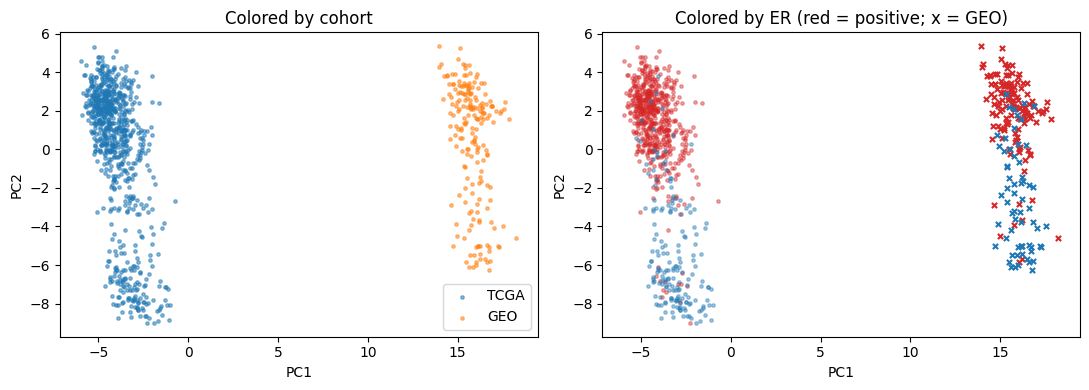

In [10]:
# Quick look at structure: PCA of both cohorts together.
pca = PCA(n_components=2, random_state=SEED).fit(pd.concat([Xtr, Xte]))
Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(*Ptr.T, s=6, alpha=.5, label="TCGA"); ax[0].scatter(*Pte.T, s=6, alpha=.5, label="GEO"); ax[0].legend(); ax[0].set_title("Colored by cohort")
for lab, col in [(1, "tab:red"), (0, "tab:blue")]:
    ax[1].scatter(*Ptr[ytr == lab].T, s=6, alpha=.4, c=col); ax[1].scatter(*Pte[yte == lab].T, s=14, marker="x", c=col)
ax[1].set_title("Colored by ER (red = positive; x = GEO)")
for a in ax: a.set_xlabel("PC1"); a.set_ylabel("PC2")
plt.tight_layout(); plt.show()

## 6. Models and nested cross-validation
Every step that learns from data (gene selection, scaling, the classifier) lives inside the `Pipeline`, so it is re-fit within each training fold. Selecting genes on the full dataset before cross-validation is one of the most common leakage mistakes in genomics classifiers.

- **Inner loop (5-fold):** grid search over number of genes and regularization.
- **Outer loop (5-fold):** unbiased performance estimate for the whole procedure.

In [11]:
def make_pipe(clf):
    return Pipeline([("select", SelectKBest(f_classif)), ("scale", StandardScaler()), ("clf", clf)])

models = {
    "logreg_l2": (
        make_pipe(LogisticRegression(max_iter=5000, class_weight="balanced")),
        {"select__k": [200, 1000, 3000], "clf__C": [0.001, 0.01, 0.1]},
    ),
    "random_forest": (
        make_pipe(RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1)),
        {"select__k": [200, 1000], "clf__max_features": ["sqrt", 0.1]},
    ),
}

inner = StratifiedKFold(5, shuffle=True, random_state=SEED)
outer = StratifiedKFold(5, shuffle=True, random_state=SEED + 1)

nested = {}
for name, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc", n_jobs=-1)
    res = cross_validate(gs, Xtr, ytr, cv=outer, scoring=["roc_auc", "balanced_accuracy"], return_estimator=True)
    nested[name] = res
    print("%-14s AUC %.3f +/- %.3f | balanced acc %.3f +/- %.3f" % (
        name, res["test_roc_auc"].mean(), res["test_roc_auc"].std(),
        res["test_balanced_accuracy"].mean(), res["test_balanced_accuracy"].std()))
    print("   params chosen per outer fold:", [e.best_params_ for e in res["estimator"]])

logreg_l2      AUC 0.957 +/- 0.015 | balanced acc 0.934 +/- 0.015
   params chosen per outer fold: [{'clf__C': 0.01, 'select__k': 200}, {'clf__C': 0.001, 'select__k': 200}, {'clf__C': 0.01, 'select__k': 200}, {'clf__C': 0.1, 'select__k': 3000}, {'clf__C': 0.01, 'select__k': 200}]
random_forest  AUC 0.954 +/- 0.018 | balanced acc 0.905 +/- 0.014
   params chosen per outer fold: [{'clf__max_features': 0.1, 'select__k': 1000}, {'clf__max_features': 0.1, 'select__k': 1000}, {'clf__max_features': 0.1, 'select__k': 1000}, {'clf__max_features': 0.1, 'select__k': 1000}, {'clf__max_features': 0.1, 'select__k': 200}]


## 7. Pick the model, then test once on the independent cohort
The model is chosen by **nested-CV AUC on TCGA only**. The GEO cohort plays no part in that choice. Picking the model that scores best on the test cohort would turn it into a second validation set and the estimate would be optimistic.

Selected by nested CV: logreg_l2
Final params: {'clf__C': 0.01, 'select__k': 200}
External AUC 0.926 (95% bootstrap CI 0.882 to 0.963) | balanced accuracy 0.567
Confusion matrix (rows = true, cols = predicted):
 [[ 64   0]
 [116  18]]


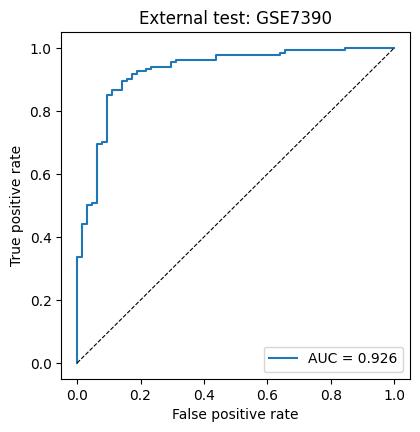

In [12]:
best_name = max(nested, key=lambda n: nested[n]["test_roc_auc"].mean())
print("Selected by nested CV:", best_name)

def fit_and_eval(name, Xa, ya, Xb, yb):
    pipe, grid = models[name]
    gs = GridSearchCV(pipe, grid, cv=inner, scoring="roc_auc", n_jobs=-1).fit(Xa, ya)
    p = gs.predict_proba(Xb)[:, 1]
    return gs, p

final, p_te = fit_and_eval(best_name, Xtr, ytr, Xte, yte)
print("Final params:", final.best_params_)

auc = roc_auc_score(yte, p_te)
bacc = balanced_accuracy_score(yte, p_te > 0.5)
rng = np.random.default_rng(SEED); boots = []
for _ in range(2000):
    i = rng.integers(0, len(yte), len(yte))
    if len(set(yte[i])) == 2: boots.append(roc_auc_score(yte[i], p_te[i]))
lo, hi = np.percentile(boots, [2.5, 97.5])
print("External AUC %.3f (95%% bootstrap CI %.3f to %.3f) | balanced accuracy %.3f" % (auc, lo, hi, bacc))
print("Confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(yte, p_te > 0.5))

fpr, tpr, _ = roc_curve(yte, p_te)
plt.figure(figsize=(4.5, 4.5)); plt.plot(fpr, tpr, label="AUC = %.3f" % auc); plt.plot([0, 1], [0, 1], "k--", lw=.8)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("External test: %s" % GEO_ID); plt.legend(); plt.show()

## 8. Sanity checks
1. **Shuffled-label control:** train on randomly permuted labels; external AUC should be near 0.5. If it is not, there is a leak.
2. **Which genes matter:** ER status is defined by ESR1 protein, so ESR1 and its known co-expressed genes (GATA3, FOXA1, XBP1, TFF1) should rank highly. If they do not, something is wrong.
3. **Ablation:** remove ESR1 and the usual ER-pathway genes and re-test. This shows whether the model relies on that one gene or on broader expression patterns.

In [13]:
y_shuf = np.random.default_rng(SEED).permutation(ytr)
_, p_shuf = fit_and_eval(best_name, Xtr, y_shuf, Xte, yte)
print("Shuffled-label external AUC: %.3f (expect about 0.5)" % roc_auc_score(yte, p_shuf))

Shuffled-label external AUC: 0.569 (expect about 0.5)


In [14]:
if best_name == "logreg_l2":
    sel = final.best_estimator_.named_steps["select"]
    genes = np.array(Xtr.columns)[sel.get_support()]
    coef = final.best_estimator_.named_steps["clf"].coef_[0]
    top = pd.Series(coef, index=genes).sort_values()
    print("Most ER-negative-associated:", list(top.head(10).index))
    print("Most ER-positive-associated:", list(top.tail(10).index[::-1]))
else:
    sel = final.best_estimator_.named_steps["select"]
    genes = np.array(Xtr.columns)[sel.get_support()]
    imp = pd.Series(final.best_estimator_.named_steps["clf"].feature_importances_, index=genes).sort_values(ascending=False)
    print("Top genes by importance:", list(imp.head(20).index))

Most ER-negative-associated: ['DSC2', 'JOSD1', 'SOX11', 'PELI1', 'CDKN2A', 'NCK2', 'UBE2E3', 'MSL3', 'PGR', 'JRKL']
Most ER-positive-associated: ['ESR1', 'FAM134B', 'DACH1', 'SCCPDH', 'KCTD3', 'EVL', 'ELF5', 'MED13L', 'C6orf211', 'ADCY9']


In [15]:
drop = [g for g in ["ESR1", "GATA3", "FOXA1", "XBP1", "TFF1", "TFF3", "PGR", "AGR2", "ANXA9", "MLPH"] if g in Xtr.columns]
keep = [g for g in Xtr.columns if g not in drop]
_, p_abl = fit_and_eval(best_name, Xtr[keep], ytr, Xte[keep], yte)
print("Removed:", drop)
print("External AUC without ER-pathway genes: %.3f (vs %.3f with them)" % (roc_auc_score(yte, p_abl), auc))

Removed: ['ESR1', 'GATA3', 'FOXA1', 'XBP1', 'TFF1', 'TFF3', 'PGR', 'AGR2', 'ANXA9', 'MLPH']
External AUC without ER-pathway genes: 0.926 (vs 0.926 with them)


## 9. Write-up

**Results.** Fill these in after your run.
- Nested CV AUC on TCGA: ___ (logistic regression), ___ (random forest)
- External AUC on GEO: ___ (95% CI ___ to ___)
- Shuffled-label control: ___ ; without ER-pathway genes: ___

**Limitations to state plainly**
- ER status is close to a one-gene readout (ESR1), so high AUC is expected. The value of this project is the *method*: leakage-free nested CV, a truly independent cohort, cross-platform handling, and control experiments. It is not a new biomarker.
- Labels come from IHC in TCGA and from each study's own call in GEO, so they are not perfectly comparable. Some disagreement is label noise rather than model error.
- One external cohort is one cohort. A second cohort would show whether the result generalizes beyond a single study.
- Per-sample ranking is a simple cross-platform fix. Alternatives (quantile normalization, ComBat, rank-based gene-pair classifiers) could be compared as an extension.

**Be able to explain, in your own words**
1. Why gene selection has to happen inside each CV fold.
2. What nested CV estimates that plain CV on the training set does not.
3. Why the external cohort was used once and not for model choice.
4. Why the shuffled-label control and the ESR1 ablation are there.
5. What the rank transform does and what it cannot fix.

**Possible extensions** (pick one if time allows): predict PAM50 subtype instead of ER status; add a second GEO cohort; compare ComBat vs rank transform; calibration curve and decision-curve analysis.

In [16]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, confusion_matrix
import numpy as np

# ---- A. The threshold problem: the model ranks GEO samples well but its scores are shifted ----
print("A. Score shift")
print("  Mean predicted P(ER+) on GEO: %.3f | true ER+ fraction in GEO: %.3f" % (p_te.mean(), yte.mean()))
print("  Median score, true ER+: %.3f | true ER-: %.3f" % (np.median(p_te[yte == 1]), np.median(p_te[yte == 0])))
print("  Fraction of GEO samples called ER+ at 0.5: %.3f" % (p_te > 0.5).mean())

# ---- B. Cohort-wise gene standardization (label-free, but uses each cohort's own gene means/SDs) ----
print("\nB. Per-cohort z-scoring of each gene (diagnostic comparison, not a replacement for the main result)")
def zcohort(df):
    sd = df.std(axis=0).replace(0, np.nan)
    return (df - df.mean(axis=0)) / sd

Ztr, Zte = zcohort(Xtr).dropna(axis=1), zcohort(Xte).dropna(axis=1)
cols = sorted(set(Ztr.columns) & set(Zte.columns))
Ztr, Zte = Ztr[cols], Zte[cols]
final_z, p_z = fit_and_eval(best_name, Ztr, ytr, Zte, yte)
print("  Params:", final_z.best_params_)
print("  External AUC: %.3f | balanced accuracy at 0.5: %.3f" % (roc_auc_score(yte, p_z), balanced_accuracy_score(yte, p_z > 0.5)))
print("  Confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(yte, p_z > 0.5))

# ---- C. Shuffled-label control, repeated (one shuffle is too noisy with n=198) ----
print("\nC. Shuffled-label control, 30 repeats with the chosen hyperparameters")
base = clone(final.best_estimator_)
perm_aucs = []
for i in range(30):
    ys = np.random.default_rng(1000 + i).permutation(ytr)
    perm_aucs.append(roc_auc_score(yte, clone(base).fit(Xtr, ys).predict_proba(Xte)[:, 1]))
print("  Mean AUC %.3f | 95%% range %.3f to %.3f | max %.3f" % (
    np.mean(perm_aucs), *np.percentile(perm_aucs, [2.5, 97.5]), np.max(perm_aucs)))

# ---- D. Is the ablation result real? Print more digits and compare predictions ----
print("\nD. Ablation checks")
drop = [g for g in ["ESR1", "GATA3", "FOXA1", "XBP1", "TFF1", "TFF3", "PGR", "AGR2", "ANXA9", "MLPH"] if g in Xtr.columns]
keep = [g for g in Xtr.columns if g not in drop]
_, p_abl = fit_and_eval(best_name, Xtr[keep], ytr, Xte[keep], yte)
print("  AUC with ER-pathway genes:    %.5f" % roc_auc_score(yte, p_te))
print("  AUC without them (10 genes):  %.5f" % roc_auc_score(yte, p_abl))
print("  Correlation of the two score vectors: %.4f" % np.corrcoef(p_te, p_abl)[0, 1])

# Stronger ablation: remove every gene the final model was allowed to use, then refit.
sel = final.best_estimator_.named_steps["select"]
used = set(np.array(Xtr.columns)[sel.get_support()])
keep2 = [g for g in Xtr.columns if g not in used]
_, p_abl2 = fit_and_eval(best_name, Xtr[keep2], ytr, Xte[keep2], yte)
print("  AUC after removing all %d genes the model used: %.3f" % (len(used), roc_auc_score(yte, p_abl2)))

A. Score shift
  Mean predicted P(ER+) on GEO: 0.201 | true ER+ fraction in GEO: 0.677
  Median score, true ER+: 0.244 | true ER-: 0.005
  Fraction of GEO samples called ER+ at 0.5: 0.091

B. Per-cohort z-scoring of each gene (diagnostic comparison, not a replacement for the main result)
  Params: {'clf__C': 0.01, 'select__k': 200}
  External AUC: 0.931 | balanced accuracy at 0.5: 0.869
  Confusion matrix (rows = true, cols = predicted):
 [[ 52  12]
 [ 10 124]]

C. Shuffled-label control, 30 repeats with the chosen hyperparameters
  Mean AUC 0.499 | 95% range 0.359 to 0.640 | max 0.667

D. Ablation checks
  AUC with ER-pathway genes:    0.92631
  AUC without them (10 genes):  0.92642
  Correlation of the two score vectors: 0.9931
  AUC after removing all 200 genes the model used: 0.898


In [17]:
# ===== Second independent cohort: used ONCE, nothing tuned on it =====
# Primary analysis  : rank transform only (same as the main pipeline).
# Secondary analysis: rank transform + per-cohort gene z-scoring (the fix found on GSE7390).
# Hyperparameters are frozen from the first run (final.best_params_). The model is re-fit on TCGA only,
# restricted to genes shared with this cohort.
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, confusion_matrix
import GEOparse, re, numpy as np, pandas as pd

GEO2_ID = "GSE20711"      # different chip (HG-U133 Plus 2) from GSE7390 (HG-U133A). Do NOT use GSE2990: it overlaps GSE7390.
GEO2_ER_KEY = None        # set by hand if auto-detection picks the wrong field

def zcohort(df):
    sd = df.std(axis=0).replace(0, np.nan)
    return (df - df.mean(axis=0)) / sd

def load_geo(geo_id):
    g = GEOparse.get_GEO(geo=geo_id, destdir="geo_cache", silent=True)
    probe = g.pivot_samples("VALUE")
    gpl_ = list(g.gpls.values())[0]
    cands = [c for c in gpl_.table.columns if c.lower().replace(" ", "").replace("_", "") in ("genesymbol", "symbol")]
    if not cands:
        raise ValueError("No gene-symbol column in platform table. Columns: %s" % list(gpl_.table.columns))
    a = gpl_.table.set_index("ID")[cands[0]].dropna().astype(str)
    a = a[~a.isin(["", "---"])].str.split(r" /// ").str[0].str.strip()
    probe = probe.loc[probe.index.intersection(a.index)]
    probe.index = a.loc[probe.index].values
    X = probe.groupby(level=0).mean().T
    rows = {}
    for name, gsm in g.gsms.items():
        d = {}
        for item in gsm.metadata.get("characteristics_ch1", []):
            if ":" in item:
                k, v = item.split(":", 1)
                d[k.strip().lower()] = v.strip()
        rows[name] = d
    return X, pd.DataFrame.from_dict(rows, orient="index")

def to_binary2(v):
    s = str(v).strip().lower()
    if "indeterminate" in s or s in ("", "nan", "na", "n/a", "unknown"): return np.nan
    if "negative" in s or s.startswith("neg") or "er-" in s or s in ("0", "-", "no", "n"): return 0
    if "positive" in s or s.startswith("pos") or "er+" in s or s in ("1", "+", "yes", "p"): return 1
    return np.nan

geo2_X, geo2_meta = load_geo(GEO2_ID)
print("Expression:", geo2_X.shape)
print("Available fields:", list(geo2_meta.columns))

key = GEO2_ER_KEY
if key is None:
    hits = [c for c in geo2_meta.columns if re.search(r"\ber\b|estrogen|er[ _]?status|^er", c)]
    if not hits:
        raise ValueError("No ER field found. Set GEO2_ER_KEY to one of: %s" % list(geo2_meta.columns))
    key = hits[0]
print("Using ER field:", key)
print(geo2_meta[key].value_counts(dropna=False))

y2_all = geo2_meta[key].map(to_binary2).dropna().astype(int)
geo2_X = geo2_X.loc[geo2_X.index.intersection(y2_all.index)]
y2 = y2_all.loc[geo2_X.index].values
print("Kept %d samples | ER+ fraction %.2f" % (len(y2), y2.mean()))
assert len(set(y2)) == 2, "Both classes must be present; check the label mapping printed above."

# Harmonize with TCGA (shared genes, per-sample ranks), exactly as in the main pipeline
common2 = sorted(set(tcga_X.columns) & set(geo2_X.columns))
A = tcga_X[common2].rank(axis=1, pct=True).dropna(axis=1)
B = geo2_X[common2].rank(axis=1, pct=True).dropna(axis=1)
common2 = sorted(set(A.columns) & set(B.columns))
A, B = A[common2], B[common2]
print("Shared genes: %d | train %s | test %s" % (len(common2), A.shape, B.shape))

def report(tag, scores, y):
    auc_ = roc_auc_score(y, scores)
    rng = np.random.default_rng(SEED); bs = []
    for _ in range(2000):
        i = rng.integers(0, len(y), len(y))
        if len(set(y[i])) == 2: bs.append(roc_auc_score(y[i], scores[i]))
    lo_, hi_ = np.percentile(bs, [2.5, 97.5])
    print("\n%s" % tag)
    print("  AUC %.3f (95%% CI %.3f to %.3f) | balanced accuracy at 0.5: %.3f" % (
        auc_, lo_, hi_, balanced_accuracy_score(y, scores > 0.5)))
    print("  Mean score %.3f vs true ER+ fraction %.3f" % (scores.mean(), y.mean()))
    print("  Confusion matrix (rows = true, cols = predicted):\n", confusion_matrix(y, scores > 0.5))
    return auc_

base = clone(final.best_estimator_)   # frozen hyperparameters from run 1
print("\nFrozen hyperparameters:", final.best_params_)

p_primary = clone(base).fit(A, ytr).predict_proba(B)[:, 1]
auc_primary = report("PRIMARY: rank transform only", p_primary, y2)

Az, Bz = zcohort(A).dropna(axis=1), zcohort(B).dropna(axis=1)
cz = sorted(set(Az.columns) & set(Bz.columns))
p_second = clone(base).fit(Az[cz], ytr).predict_proba(Bz[cz])[:, 1]
auc_second = report("SECONDARY: per-cohort gene z-scoring", p_second, y2)

perm = []
for i in range(20):
    ys = np.random.default_rng(2000 + i).permutation(ytr)
    perm.append(roc_auc_score(y2, clone(base).fit(A, ys).predict_proba(B)[:, 1]))
print("\nShuffled-label control (20 repeats): mean AUC %.3f, range %.3f to %.3f" % (
    np.mean(perm), *np.percentile(perm, [2.5, 97.5])))

# Summary across both external cohorts (GSE7390 numbers come from the earlier cells)
summary = pd.DataFrame({
    "cohort": ["GSE7390", GEO2_ID],
    "n": [len(yte), len(y2)],
    "AUC (primary)": [roc_auc_score(yte, p_te), auc_primary],
    "bal. acc @0.5 (primary)": [balanced_accuracy_score(yte, p_te > 0.5), balanced_accuracy_score(y2, p_primary > 0.5)],
    "AUC (z-scored)": [roc_auc_score(yte, p_z), auc_second],
    "bal. acc @0.5 (z-scored)": [balanced_accuracy_score(yte, p_z > 0.5), balanced_accuracy_score(y2, p_second > 0.5)],
}).round(3)
print("\n", summary.to_string(index=False))

Expression: (90, 22880)
Available fields: ['quality control', 'methylation barcode', 'subtypeihc', 'grade', 'node', 'size (bin)', 'age (bin)', 'er status', 'her2 status', 'subtypege', 'e.rfs', 't.rfs', 'e.os', 't.os']
Using ER field: er status
er status
0     45
1     42
NA     3
Name: count, dtype: int64
Kept 87 samples | ER+ fraction 0.48
Shared genes: 16698 | train (780, 16698) | test (87, 16698)

Frozen hyperparameters: {'clf__C': 0.01, 'select__k': 200}

PRIMARY: rank transform only
  AUC 0.850 (95% CI 0.758 to 0.928) | balanced accuracy at 0.5: 0.573
  Mean score 0.204 vs true ER+ fraction 0.483
  Confusion matrix (rows = true, cols = predicted):
 [[43  2]
 [34  8]]

SECONDARY: per-cohort gene z-scoring
  AUC 0.869 (95% CI 0.783 to 0.940) | balanced accuracy at 0.5: 0.808
  Mean score 0.634 vs true ER+ fraction 0.483
  Confusion matrix (rows = true, cols = predicted):
 [[32 13]
 [ 4 38]]

Shuffled-label control (20 repeats): mean AUC 0.484, range 0.328 to 0.624

   cohort   n  AU